<a href="https://colab.research.google.com/github/samkenzie/predicting-electrode-transport-properties/blob/main/Dataset_Breakdown.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dataset Breakdown

The purpose of this file is to explore the dataset of 100,000 computer-generated images of Lithium-ion battery electrode microstructures.

In [1]:
#0. Imports
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import glob #https://docs.python.org/3/library/glob.html
from PIL import Image #https://pillow.readthedocs.io/en/stable/reference/Image.html
from scipy import ndimage

In [2]:
#1. Import data:
!unzip -q /content/images_aps360.zip -d /content/images
!unzip -q /content/diffusion_aps360.zip -d /content/texts

In [3]:
#2. Loading/storing the effective diffusivity and conductivity values
text_dir = "/content/texts"
eff_diff, eff_cond = [], []

for path in glob.glob("/content/texts/dispersion/*.txt"):
    with open(path) as fh:
        vals = fh.read().split() #Values separated by a new line, thus splits!
        eff_diff.append(float(vals[0]))
        eff_cond.append(float(vals[1]))

print(f"Loaded {len(eff_diff)} files")

Loaded 100000 files


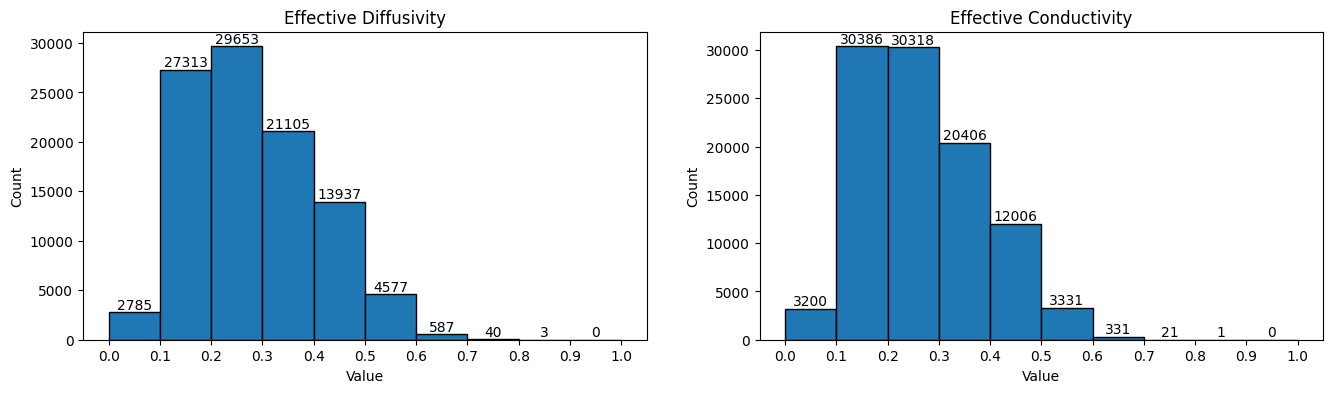

In [4]:
#3. Plotting effective diffusivity and conductivity
bins = np.linspace(0, 1, 11) #11 edges
fig, axes = plt.subplots(1, 2, figsize=(16, 4))

for ax, data, title in zip(axes, [eff_diff, eff_cond], ["Effective Diffusivity", "Effective Conductivity"]):
    ax.hist(data, bins=bins, edgecolor="black")
    ax.set_title(title)
    ax.set_xlabel("Value")
    ax.set_ylabel("Count")
    ax.set_xticks(bins)
    ax.bar_label(ax.containers[0])

There is an obvious bias for effective diffusivity and conductivity values primarily between 0.1 and 0.5.

In [5]:
#4. Import image data
img_ids, img_pixels = [], []
for path in glob.glob("/content/images/64/*.tif"):
    img_ids.append(int(Path(path).stem)) #123.tif -> 123
    img_pixels.append(np.asarray(Image.open(path)))

img_ids = np.array(img_ids)
img_pixels = np.stack(img_pixels) #Expected (100000, 64, 64)

print(f"Loaded {len(img_ids)} images")
print(f"Array shape {img_pixels.shape}")

Loaded 100000 images
Array shape (100000, 64, 64)


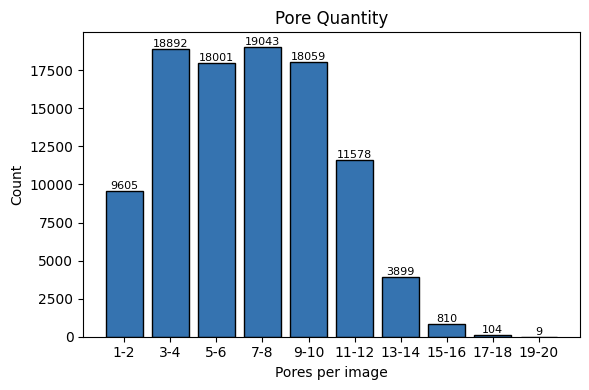

In [6]:
counts = np.array([ndimage.label(img == 0)[1] for img in img_pixels]) #Count pores per image (connected components)

#Split into 1-2, 3-4, ..., 19-20
edges = np.arange(0.5, 21, 2) #Edges split
hist, _ = np.histogram(counts, bins=edges)
labels = [f"{i}-{i+1}" for i in range(1, 20, 2)]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, hist, color="#3573b0", edgecolor="black")
ax.bar_label(bars, fontsize=8)
ax.set_xlabel("Pores per image")
ax.set_ylabel("Count")
ax.set_title("Pore Quantity")
plt.tight_layout()
plt.show()